### Build a basic chatbot with Langgraph(Graph API)

In [1]:
from typing import  Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The 'add_messages' function
    # will append messages to this list.
    messages: Annotated[list,add_messages]
graph_builder = StateGraph(State)

In [3]:
graph_builder

In [4]:
import os 
from dotenv import load_dotenv
load_dotenv()


True

In [5]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")

In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001FF6FC33380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001FF6FC33E00>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
##Node Functionalities

def chatbot(state: State):
    return {"messages":[llm.invoke(state["messages"])]}

In [8]:
##Adding the chatbot node to the graph
graph_builder.add_node("llmchatbot",chatbot)

##Adding edges to the graph
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

##compiling the graph
graph = graph_builder.compile()

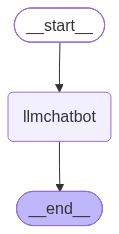

In [9]:
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e)

In [10]:
response=graph.invoke({"messages":[{"role":"user","content":"Hello, how are you?"}]})

In [11]:
graph.invoke({"messages":[{"role":"user","content":"Hello,?"}]})

{'messages': [HumanMessage(content='Hello,?', additional_kwargs={}, response_metadata={}, id='76aabe5f-182f-44bb-a3f5-866f08854cc0'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hello,?" Likely wants greeting. We respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 74, 'total_tokens': 108, 'completion_time': 0.072015654, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.014139712, 'prompt_tokens_details': None, 'queue_time': 0.229599594, 'total_time': 0.086155366}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5a93aea882', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12736-2ded-7890-9d3a-2461cf952a18-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 74, 'output_tokens': 34, 'total_tokens': 108, 'output_token_details': {'reasoning': 16}})]}

In [12]:
response["messages"][-1].content

"Hello! I'm doing great, thank you for asking. How can I assist you today?"

In [13]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)   

Hello! I'm doing great, thanks for asking. How can I assist you today?


### ChatBot with Tool

In [14]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is the capital of France?")

{'query': 'What is the capital of France?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.worldatlas.com/articles/what-is-the-capital-of-france.html',
   'title': 'What is the Capital of France?',
   'content': 'Paris is the capital city of France. The city has an approximate area of 41 square miles with a population of 2,206,488 people as of 2018. Contrary to popular belief, the name of the city did not come from the Paris in Greek myths. Instead, the name Paris is derived from the city’s initial inhabitants who were part of the Celtic Parisii tribe. Sometimes, the city is called the City of Light for two reasons; it was among the first cities to adopt gas for lighting the streets and its role during [...] As the capital city of France, the city plays host to the national government of France. Even the official residence of the president is in the city at the Élysée Palace while the Prime Minister is housed at the Hôtel Matignon. The S

In [15]:
### Custom Function
def multiply(a: int, b: int) -> int:
    """ Multilplies two numbers and returns the result. 
        Args:
            a (int): The first number.
            b (int): The second number.

        Returns:
            int: The product of the two numbers.
    """
    return a * b

In [16]:
tools=[tool,multiply]

In [17]:
llm_with_tool=llm.bind_tools(tools)

In [18]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.9', 'langchain': '1.4.4'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001FF6FC33380>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001FF6FC33E00>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

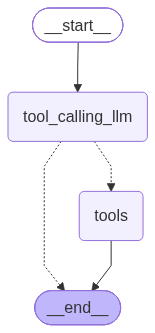

In [19]:
### State Graph with Tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode,tools_condition

### Node Definition
def tool_calling_llm(state: State):
    # Call the LLM with the tools bound to it
    response = llm_with_tool.invoke(state["messages"])
    return {"messages": [response]}

### Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

### Adding edges to the graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the LLM decides to use a tool, go to the tools node
    # otherwise, go to the END node                         
    tools_condition)
builder.add_edge("tools", END)

graph_with_tools = builder.compile()

from IPython.display import Image, display

try:
    display(Image(graph_with_tools.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e) 

In [20]:
response = graph_with_tools.invoke({"messages":[{"role":"user","content":"What is the recent AI news?"}]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_b1364cdf-1f17-4018-b824-60e9fca11d8e)
 Call ID: fc_b1364cdf-1f17-4018-b824-60e9fca11d8e
  Args:
    query: latest AI news
    search_depth: fast
    time_range: week
================================= Tool Message =================================
Name: tavily_search

No search results found for 'latest AI news'. Suggestions: Remove time_range argument. Try modifying your search parameters with one of these approaches.


In [21]:
response = graph_with_tools.invoke({"messages":[{"role":"user","content":"What is 3 multiply 4?"}]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 3 multiply 4?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_0cd304ad-842e-4655-90c1-ce85d4457370)
 Call ID: fc_0cd304ad-842e-4655-90c1-ce85d4457370
  Args:
    a: 3
    b: 4
================================= Tool Message =================================
Name: multiply

12


In [22]:
response = graph_with_tools.invoke({"messages":[{"role":"user","content":"Give me recent ai news and multiply 4 by 5?"}]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and multiply 4 by 5?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_fe8caf13-e2e7-4f85-afbf-6b61bdd23587)
 Call ID: fc_fe8caf13-e2e7-4f85-afbf-6b61bdd23587
  Args:
    query: latest AI news 2024 October
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2024 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://docs.cloud.google.com/vertex-ai/docs/release-notes", "title": "Vertex AI release notes  |  Google Cloud Documentation", "content": "## October 08, 2024\n\nVertex AI\n\nv1\n\nFeature\n\nVector Search Private Service Connect automation\n\nDeploying an index with Private Service Connect automation is generally available (GA). You ca

### React Agent Architecture

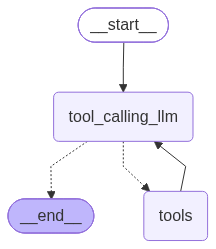

In [23]:
### State Graph with Tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode,tools_condition

### Node Definition
def tool_calling_llm(state: State):
    # Call the LLM with the tools bound to it
    response = llm_with_tool.invoke(state["messages"])
    return {"messages": [response]}

### Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

### Adding edges to the graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the LLM decides to use a tool, go to the tools node
    # otherwise, go to the END node                         
    tools_condition)
builder.add_edge("tools", "tool_calling_llm")

graph_with_tools = builder.compile()

from IPython.display import Image, display

try:
    display(Image(graph_with_tools.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e) 

In [24]:
response = graph_with_tools.invoke({"messages":[{"role":"user","content":"Give me recent ai news and multiply 4 by 5?"}]})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and multiply 4 by 5?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_e2e50221-1f0d-40e5-b83e-aaae71a2e474)
 Call ID: fc_e2e50221-1f0d-40e5-b83e-aaae71a2e474
  Args:
    a: 4
    b: 5
================================= Tool Message =================================
Name: multiply

20
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_993d6f14-c346-4035-8494-033019dabb80)
 Call ID: fc_993d6f14-c346-4035-8494-033019dabb80
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://techstartups.com/2026/10/0

### Adding Memory Agentic Graph

In [25]:
response = graph_with_tools.invoke({"messages":"Hello, My name is Abhishek"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello, My name is Abhishek
================================== Ai Message ==================================

Hello Abhishek! 👋 Nice to meet you. How can I assist you today?


In [26]:
response = graph_with_tools.invoke({"messages":"Hello,what is my name"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello,what is my name
================================== Ai Message ==================================

I don’t actually have any information about you, so I don’t know your name. 😊 If you’d like me to address you by name, just let me know what it is!


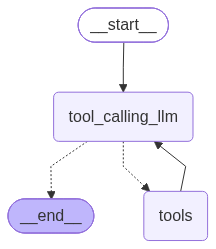

In [27]:
### State Graph with Tools
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory_saver = MemorySaver()

### Node Definition
def tool_calling_llm(state: State):
    # Call the LLM with the tools bound to it
    response = llm_with_tool.invoke(state["messages"])
    return {"messages": [response]}

### Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

### Adding edges to the graph
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm", 
    # If the LLM decides to use a tool, go to the tools node
    # otherwise, go to the END node                         
    tools_condition)
builder.add_edge("tools", "tool_calling_llm")

graph_with_tools = builder.compile(checkpointer=memory_saver)

from IPython.display import Image, display

try:
    display(Image(graph_with_tools.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e) 

In [28]:
config={"configurable":{"thread_id":"1"}}
response = graph_with_tools.invoke({"messages":"Hello, My name is Abhishek"},config=config)
for m in response["messages"]:
    m.pretty_print()


================================ Human Message =================================

Hello, My name is Abhishek
================================== Ai Message ==================================

Hello Abhishek! 👋 Nice to meet you. How can I assist you today?


In [29]:
response = graph_with_tools.invoke({"messages":"Hello,what is my name"},config=config)

response["messages"][-1].content
# for m in response["messages"]:
#     m.pretty_print()

'Your name is **Abhishek**. 😊'

### Streaming

In [30]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [31]:
def superbot(state: State):
    # Call the LLM with the tools bound to it
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

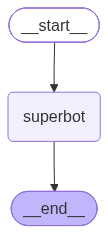

In [32]:
graph=StateGraph(State)

#node
graph.add_node("superbot", superbot)

#edges
graph.add_edge(START,"superbot")
graph.add_edge("superbot",END)

graph_builder=graph.compile(checkpointer=memory)

#Display the graph
from IPython.display import Image, display
try:    
    display(Image(graph_builder.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e)

In [33]:
## Invoking the graph

config={"configurable":{"thread_id":"1"}}
graph_builder.invoke({"messages":"Hello, My name is Abhishek, and I like cricket"},config=config)


{'messages': [HumanMessage(content='Hello, My name is Abhishek, and I like cricket', additional_kwargs={}, response_metadata={}, id='1ebd9be1-4fde-42be-815b-3dbf370b73d6'),
  AIMessage(content='Hello Abhishek! Nice to meet you. 🎉  \nCricket is such an exciting sport—do you have a favorite team or player you follow? Whether it’s the thrill of a Test match, the fast‑paced action of T20, or the classic charm of ODIs, I’d love to hear what you enjoy most about the game!', additional_kwargs={'reasoning_content': 'The user says "Hello, My name is Abhishek, and I like cricket". Likely they are just greeting. We should respond friendly, ask about their interest, maybe ask about favorite team or player. Follow guidelines: be helpful, friendly. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 137, 'prompt_tokens': 84, 'total_tokens': 221, 'completion_time': 0.284210665, 'completion_tokens_details': {'reasoning_tokens': 56}, 'prompt_time': 0.003204622, 'prompt_tokens_d

Methods : .stream() & astream()
- values
- update

In [34]:
config={"configurable":{"thread_id":"3"}}
for chunk in graph_builder.stream({"messages":"Hello, My name is Abhishek, and I like cricket"},config=config,stream_mode="updates"):
    print(chunk)
    # for value in chunk.values():
        # print(value["messages"][-1].content)

{'superbot': {'messages': [AIMessage(content='Hi Abhishek! 👋 Great to meet you. How’s the cricket season treating you? Do you have a favorite team or player you’re cheering for? 🏏✨', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. The assistant should respond friendly, maybe ask about cricket preferences. No policy conflict. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 84, 'total_tokens': 158, 'completion_time': 0.152376288, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003862245, 'prompt_tokens_details': None, 'queue_time': 0.33773489, 'total_time': 0.156238533}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12736-abeb-7a32-9879-8855aeb40359-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 84, 'output_tokens': 

In [35]:
for chunk in graph_builder.stream({"messages":"Hello, My name is Abhishek, and I like cricket"},config=config,stream_mode="values"):
    print(chunk)
    # for value in chunk.values():
        # print(value["messages"][-1].content)

{'messages': [HumanMessage(content='Hello, My name is Abhishek, and I like cricket', additional_kwargs={}, response_metadata={}, id='3a2ffb61-56a6-4d3e-bfb4-6f7f5fe6f803'), AIMessage(content='Hi Abhishek! 👋 Great to meet you. How’s the cricket season treating you? Do you have a favorite team or player you’re cheering for? 🏏✨', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. The assistant should respond friendly, maybe ask about cricket preferences. No policy conflict. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 84, 'total_tokens': 158, 'completion_time': 0.152376288, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003862245, 'prompt_tokens_details': None, 'queue_time': 0.33773489, 'total_time': 0.156238533}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}

In [36]:
for chunk in graph_builder.stream({"messages":" I also like badminton"},config=config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hello, My name is Abhishek, and I like cricket', additional_kwargs={}, response_metadata={}, id='3a2ffb61-56a6-4d3e-bfb4-6f7f5fe6f803'), AIMessage(content='Hi Abhishek! 👋 Great to meet you. How’s the cricket season treating you? Do you have a favorite team or player you’re cheering for? 🏏✨', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. The assistant should respond friendly, maybe ask about cricket preferences. No policy conflict. So respond.'}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 84, 'total_tokens': 158, 'completion_time': 0.152376288, 'completion_tokens_details': {'reasoning_tokens': 28}, 'prompt_time': 0.003862245, 'prompt_tokens_details': None, 'queue_time': 0.33773489, 'total_time': 0.156238533}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}

In [38]:
config={"configurable":{"thread_id":"4"}}
async for chunk in graph_builder.astream_events({"messages":"Hello, My name is Abhishek, and I like cricket"},config=config,version="v2"):
    print(chunk)
    # for value in chunk.values():
        # print(value["messages"][-1].content)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hello, My name is Abhishek, and I like cricket'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1273a-a44f-7033-bc4e-46d4298d5e89', 'metadata': {'thread_id': '4', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hello, My name is Abhishek, and I like cricket', additional_kwargs={}, response_metadata={}, id='6e5d280e-dd18-48db-8c77-469a92584418')]}}, 'name': 'superbot', 'tags': ['graph:step:1'], 'run_id': '01a1273a-a454-77d3-b7df-b2c5202c6e62', 'metadata': {'thread_id': '4', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'superbot', 'langgraph_triggers': ('branch:to:superbot',), 'langgraph_path': ('__pregel_pull', 'superbot'), 'langgraph_checkpoint_ns': 'superbot:d165b55a-c94c-3824-e8be-bf793c7d8bcf'}, 'parent_ids': ['01a1273a-a44f-7033-bc4e-46d4298d5e89']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [